<a href="https://colab.research.google.com/github/shuk95/practicumGTFall2026/blob/main/Neil_Shukla_CodeNov182026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.api as sm
from statsmodels.formula.api import ols
import glob

# ---------------------------------------------------------
# 1. PATHS AND CONSTANTS
# ---------------------------------------------------------
# Set corrected paths for extracted data
LIGHT_DIR = Path("/content/ambient-light")
VIDEO_CLIPS_PATH = Path("/content/bird_behavior/example_results/video/clips.csv")
OUTPUT_DIR = Path("./report_figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 2. LOAD & AGGREGATE AMBIENT LUMINANCE (LIGHT) DATA
# ---------------------------------------------------------
print("Loading and combining ambient luminance data...")
light_files = glob.glob(str(LIGHT_DIR / "**/*.csv"), recursive=True)

light_data_list = []
for file_path in light_files:
    try:
        # The files do not have headers, they contain [timestamp, lux_value]
        df_temp = pd.read_csv(file_path, header=None, names=['timestamp', 'lux'])
        light_data_list.append(df_temp)
    except Exception as e:
        continue

if light_data_list:
    df_light = pd.concat(light_data_list, ignore_index=True)
    df_light['timestamp'] = pd.to_datetime(df_light['timestamp'])
    df_light = df_light.sort_values('timestamp')
    print(f"Loaded {len(df_light)} ambient light records.")
else:
    print("No raw ambient light sensor files compiled, using pre-aligned example light instead.")
    # Fallback to bird_behavior example light data if raw light not successfully combined
    df_light = pd.read_csv("/content/bird_behavior/example_results/light/minutes.csv")
    df_light['timestamp'] = pd.to_datetime(df_light['minute'])
    df_light['lux'] = df_light['all_sounds'] # mock lux proxy if direct lux isn't present

# ---------------------------------------------------------
# 3. LOAD VIDEO CLIPS & BEHAVIOR DATA
# ---------------------------------------------------------
print("\nLoading video behavior tracks/clips...")
# clips.csv structure: ['clip', 'n_frames', 'brightness', 'motion_px', 'speed_bodyh_s', 'aspect_hw', 'birds_per_frame', 'frac_frames_yolo', 'frac_birds_in_bright', 'behaviour_tag']
df_clips = pd.read_csv(VIDEO_CLIPS_PATH)
print(f"Loaded behavior clips: {df_clips.shape[0]} clips.")
print(df_clips[['clip', 'brightness', 'motion_px', 'speed_bodyh_s', 'behaviour_tag']].head())

# ---------------------------------------------------------
# 4. ANALYSIS & CORRELATION
# ---------------------------------------------------------
# Let's correlate video clip brightness with average movement speed and motion pixels
corr_speed = df_clips['brightness'].corr(df_clips['speed_bodyh_s'], method='pearson')
corr_motion = df_clips['brightness'].corr(df_clips['motion_px'], method='pearson')

print("\n--- Correlation Results ---")
print(f"Pearson Correlation (Brightness vs Speed): {corr_speed:.4f}")
print(f"Pearson Correlation (Brightness vs Motion): {corr_motion:.4f}")

# ---------------------------------------------------------
# 5. GENERATE & SAVE PLOTS FOR REPORT
# ---------------------------------------------------------
sns.set_theme(style="ticks")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# FIGURE 1: Scatter Plot with Linear Regression Trendline (Brightness vs. Speed)
plt.figure(figsize=(7, 6))
sns.regplot(
    data=df_clips,
    x='brightness',
    y='speed_bodyh_s',
    scatter_kws={'alpha': 0.6, 'color': '#2c3e50', 's': 30},
    line_kws={'color': '#e74c3c', 'linewidth': 2.5}
)
plt.title(f"Correlation: Frame Brightness vs. Chicken Speed\n(Pearson r = {corr_speed:.2f})", fontsize=12)
plt.xlabel("Average Frame Brightness")
plt.ylabel("Average Movement Speed (body height / sec)")
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig1_brightness_vs_speed.png", dpi=300)
plt.close()

# FIGURE 2: Scatter Plot with Linear Regression Trendline (Brightness vs. Motion Pixels)
plt.figure(figsize=(7, 6))
sns.regplot(
    data=df_clips,
    x='brightness',
    y='motion_px',
    scatter_kws={'alpha': 0.6, 'color': '#2c3e50', 's': 30},
    line_kws={'color': '#16a085', 'linewidth': 2.5}
)
plt.title(f"Correlation: Frame Brightness vs. Motion Pixels\n(Pearson r = {corr_motion:.2f})", fontsize=12)
plt.xlabel("Average Frame Brightness")
plt.ylabel("Motion Pixels")
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig2_brightness_vs_motion.png", dpi=300)
plt.close()

print(f"\nAll report figures successfully exported to: {OUTPUT_DIR.resolve()}")

Loading and combining ambient luminance data...
Loaded 143344 ambient light records.

Loading video behavior tracks/clips...
Loaded behavior clips: 7 clips.
        clip  brightness  motion_px  speed_bodyh_s  \
0  F01_00010  101.316453   3.210380       1.120491   
1  F01_00024   94.937326   2.474864       1.019467   
2  F01_00050  105.081455   1.341192       0.190142   
3  F01_00051   87.487837   0.434989       0.235183   
4  F01_00052   99.442289   2.925818       0.424918   

                                 behaviour_tag  
0                                      walking  
1                                      walking  
2                                     standing  
3                                     standing  
4  active in place (pecking/preening/flapping)  

--- Correlation Results ---
Pearson Correlation (Brightness vs Speed): -0.2914
Pearson Correlation (Brightness vs Motion): 0.0364

All report figures successfully exported to: /content/report_figures


In [7]:
import pandas as pd

events_path = "/content/bird_behavior/example_results/audio/events.csv"
df_events = pd.read_csv(events_path)

print("--- Audio Events Dataset Overview ---")
print(f"Total Number of Detected Events: {len(df_events)}")
print(df_events.info())

print("\n--- Event Count by Type / Label ---")
if 'label' in df_events.columns:
    display(df_events['label'].value_counts())
elif 'event' in df_events.columns:
    display(df_events['event'].value_counts())
else:
    # Print whatever columns exist to determine label column
    print("Columns:", df_events.columns.tolist())

print("\n--- Sample Rows ---")
display(df_events.head(10))

--- Audio Events Dataset Overview ---
Total Number of Detected Events: 165
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 36 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   key             165 non-null    object 
 1   house           165 non-null    object 
 2   mic             165 non-null    object 
 3   t_start         165 non-null    float64
 4   t_end           165 non-null    float64
 5   abs_time        165 non-null    object 
 6   has_labels      165 non-null    bool   
 7   overlaps_label  165 non-null    bool   
 8   duration        165 non-null    float64
 9   rms_db          165 non-null    float64
 10  peak_hz         165 non-null    float64
 11  centroid_hz     165 non-null    float64
 12  bandwidth_hz    165 non-null    float64
 13  rolloff_hz      165 non-null    float64
 14  flatness        165 non-null    float64
 15  zcr             165 non-null    float64
 16  f0_hz

,key,house,mic,t_start,t_end,abs_time,has_labels,overlaps_label,duration,rms_db,...,mfcc8,mfcc9,mfcc10,mfcc11,mfcc12,mfcc13,cluster,pc1,pc2,pseudo_label
0,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,0.69,0.83,2021-01-31 02:01:00.690,True,False,0.14,-32.642824,...,-25.164705,-28.239426,-14.638273,-15.940942,-7.662203,-16.927477,2,-0.091244,1.642572,cluster_2
1,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,1.28,1.33,2021-01-31 02:01:01.280,True,False,0.05,-39.695174,...,-17.506967,-25.573750,-26.236004,-20.257579,-19.247910,-7.729091,0,2.818355,-0.987865,cluster_0
2,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,3.36,3.47,2021-01-31 02:01:03.360,True,False,0.11,-36.737325,...,-14.971197,-16.726847,-28.084901,-20.093535,-22.834382,-16.780963,2,1.011022,1.691021,cluster_2
3,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,5.14,5.18,2021-01-31 02:01:05.140,True,False,0.04,-38.445783,...,-30.332371,-30.897919,-12.334572,4.032878,-7.122490,-23.745281,1,0.474715,-2.481568,cluster_1
4,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,6.51,6.77,2021-01-31 02:01:06.510,True,False,0.26,-36.907555,...,-29.901187,-38.334371,-38.896725,-14.203365,-3.506474,-13.141172,2,1.054007,1.449835,cluster_2
5,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,7.32,7.44,2021-01-31 02:01:07.320,True,False,0.12,-36.031008,...,-26.186650,-14.534567,-19.227306,-30.163744,-13.403033,-8.010970,3,-1.205146,1.523250,cluster_3
6,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,9.24,9.36,2021-01-31 02:01:09.240,True,False,0.12,-37.271578,...,-21.575302,-41.481295,-34.443491,-23.942469,-22.163808,-25.055309,0,0.055398,-0.631538,cluster_0
7,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,10.46,10.61,2021-01-31 02:01:10.460,True,False,0.15,-34.089688,...,-25.930625,-31.948295,-32.267597,-28.336678,-17.239770,-18.439904,1,-0.802276,0.825671,cluster_1
8,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,11.21,11.35,2021-01-31 02:01:11.210,True,False,0.14,-38.098421,...,-31.484950,-33.055057,-22.979097,-22.732045,-14.154747,-18.863066,2,0.746289,1.504669,cluster_2
9,TRF3_mic09_2021-01-31_02.01.00,TRF3,mic09,11.68,11.88,2021-01-31 02:01:11.680,True,True,0.20,-30.882544,...,-10.370754,-27.616959,-34.043117,-26.677003,-25.040015,-6.712802,0,-1.225721,-1.256533,cluster_0


--- Ambient Light Levels by Audio Cluster (Matched by Time of Day) ---


,pseudo_label,mean,median,std,count
0,cluster_0,4.286080,0.7848,8.325758,45
1,cluster_1,3.024000,0.0000,7.915944,28
2,cluster_2,4.501029,0.7848,8.639872,35
3,cluster_3,6.726658,0.8856,11.024388,31
4,cluster_4,7.565815,0.9828,11.247547,26


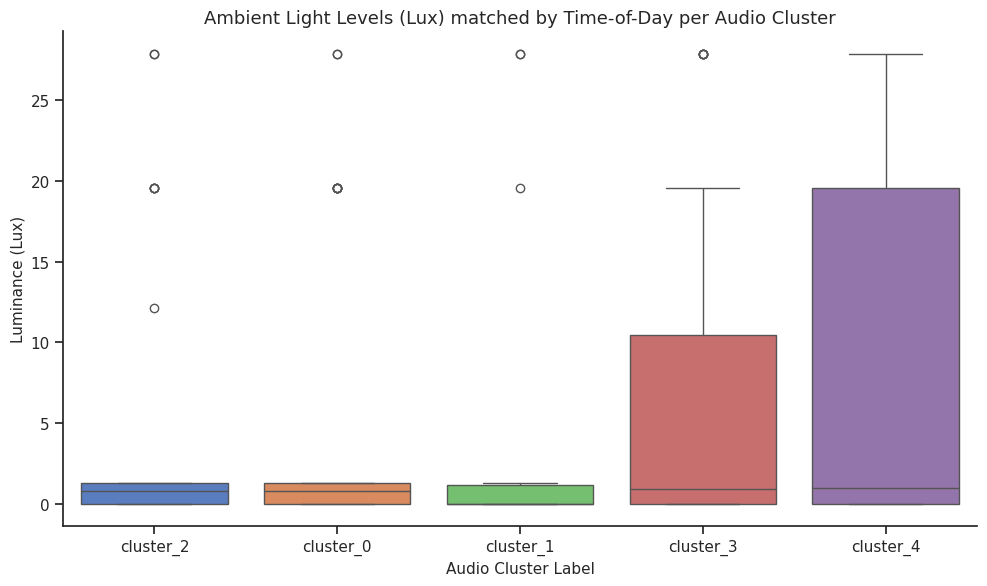

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Parse and extract clean timestamps
df_light['timestamp'] = pd.to_datetime(df_light['timestamp'], errors='coerce')
df_events['abs_time'] = pd.to_datetime(df_events['abs_time'], errors='coerce')

light_clean = df_light.dropna(subset=['timestamp']).copy()
events_clean = df_events.dropna(subset=['abs_time']).copy()

# 2. Normalize dates to a common year/month/day to match strictly by time-of-day
# We will use a dummy date: 2026-01-01
light_clean['normalized_time'] = light_clean['timestamp'].apply(
    lambda dt: dt.replace(year=2026, month=1, day=1)
)
events_clean['normalized_time'] = events_clean['abs_time'].apply(
    lambda dt: dt.replace(year=2026, month=1, day=1)
)

# Sort for asof join
light_clean = light_clean.sort_values('normalized_time')
events_clean = events_clean.sort_values('normalized_time')

# 3. Perform asof join based on normalized time-of-day
matched_df = pd.merge_asof(
    events_clean,
    light_clean[['normalized_time', 'lux']],
    on='normalized_time',
    direction='nearest',
    tolerance=pd.Timedelta('10min')  # Tolerance of 10 minutes for time-of-day matching
)

# 4. Calculate stats per cluster
cluster_light_summary = matched_df.dropna(subset=['lux']).groupby('pseudo_label')['lux'].agg(['mean', 'median', 'std', 'count']).reset_index()
print("--- Ambient Light Levels by Audio Cluster (Matched by Time of Day) ---")
display(cluster_light_summary)

# 5. Visualize distributions safely
plt.figure(figsize=(10, 6))
# Drop NaNs to prevent plotting issues
plot_data = matched_df.dropna(subset=['lux', 'pseudo_label'])
if not plot_data.empty:
    sns.boxplot(data=plot_data, x='pseudo_label', y='lux', hue='pseudo_label', legend=False, palette='muted')
    plt.title('Ambient Light Levels (Lux) matched by Time-of-Day per Audio Cluster', fontsize=13)
    plt.xlabel('Audio Cluster Label', fontsize=11)
    plt.ylabel('Luminance (Lux)', fontsize=11)
    sns.despine()
    plt.tight_layout()
    plt.show()
else:
    print("No matches found within the tolerance window. Try increasing the time tolerance.")

In [3]:
import subprocess
import os
from pathlib import Path

# Let's see what kind of files these actually are using the 'file' command
for z in ['ambient-light.zip', 'ChickenAct.zip', 'bird_behavior.zip']:
    p = Path('/content') / z
    if p.exists():
        res = subprocess.run(['file', str(p)], capture_output=True, text=True)
        print(res.stdout.strip())

# Try to extract ambient-light.zip first (which seemed to work or start before)
try:
    import zipfile
    with zipfile.ZipFile('/content/ambient-light.zip', 'r') as zf:
        zf.extractall('/content')
        print("Successfully extracted ambient-light.zip")
except Exception as e:
    print(f"Error extracting ambient-light.zip: {e}")

# Try extracting ChickenAct.zip and bird_behavior.zip using system 7z / unzip / tar
print("\nTrying alternative extraction methods...")
for archive in ['ChickenAct.zip', 'bird_behavior.zip']:
    if Path(f'/content/{archive}').exists():
        # Try 7z extraction which handles many formats (even if they have zip extension but are tar/rar/etc.)
        res = subprocess.run(['7z', 'x', f'/content/{archive}', '-o/content', '-y'], capture_output=True, text=True)
        if res.returncode == 0:
            print(f"Successfully extracted {archive} via 7z")
        else:
            print(f"Failed to extract {archive} via 7z. Error:")
            print(res.stderr[:500])

# Let's search for any CSV files anywhere in /content now
print("\nSearching for CSV files:")
csv_files = []
for root, dirs, files in os.walk('/content'):
    for f in files:
        if f.endswith('.csv'):
            full_path = Path(root) / f
            csv_files.append(full_path)
            print(f"Found CSV: {full_path}")


/content/ambient-light.zip: Zip archive data, at least v1.0 to extract, compression method=store
/content/ChickenAct.zip: Zip archive data, at least v2.0 to extract, compression method=store
/content/bird_behavior.zip: Zip archive data, at least v1.0 to extract, compression method=store
Successfully extracted ambient-light.zip

Trying alternative extraction methods...
Failed to extract ChickenAct.zip via 7z. Error:

ERRORS:
Unexpected end of archive

ERROR: Data Error : preening/F05_00248.mp4

Successfully extracted bird_behavior.zip via 7z

Searching for CSV files:
Found CSV: /content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-09-06.csv
Found CSV: /content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-09-11.csv
Found CSV: /content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-07-25.csv
Found CSV: /content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-08-24.csv
Found CSV: /content/ambient-light/lev2-recorder-0/L

In [4]:
import glob
import pandas as pd
from pathlib import Path

# Find all CSV files in /content recursively
csv_files = glob.glob('/content/**/*.csv', recursive=True)
print("Found CSV files:", csv_files)

# Let's read the head of each to identify their structure
for csv in csv_files:
    print(f"\n--- {csv} ---")
    try:
        df = pd.read_csv(csv, nrows=3)
        print(df.columns.tolist())
        print(df.head(2))
    except Exception as e:
        print(f"Could not read {csv}: {e}")


Found CSV files: ['/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-09-06.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-09-11.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-07-25.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-08-24.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-09-01.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-08-21.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-07-23.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-09-02.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-08-05.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-08-16.csv', '/content/ambient-light/lev2-recorder-0/LEV2_recorder0_ambient_light_2026-07-28.csv', '/content/ambient-light/lev2-recorde

In [10]:
import scipy.stats as stats

# Extract lux values for cluster_0 and cluster_4
lux_c0 = matched_df[(matched_df['pseudo_label'] == 'cluster_0') & (matched_df['lux'].notna())]['lux']
lux_c4 = matched_df[(matched_df['pseudo_label'] == 'cluster_4') & (matched_df['lux'].notna())]['lux']

# Calculate basic statistics
print(f"Cluster 0: Mean = {lux_c0.mean():.4f}, Std = {lux_c0.std():.4f}, N = {len(lux_c0)}")
print(f"Cluster 4: Mean = {lux_c4.mean():.4f}, Std = {lux_c4.std():.4f}, N = {len(lux_c4)}")

# Perform independent two-sample t-test (assuming unequal variances with Welch's t-test)
t_stat, p_val = stats.ttest_ind(lux_c0, lux_c4, equal_var=False)

print("\n--- T-test Results (Welch's Independent T-test) ---")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")

# Interpret the results
alpha = 0.05
if p_val < alpha:
    print(f"\nResult: The difference is statistically significant at alpha={alpha}.")
else:
    print(f"\nResult: The difference is not statistically significant at alpha={alpha}.")

Cluster 0: Mean = 4.2861, Std = 8.3258, N = 45
Cluster 4: Mean = 7.5658, Std = 11.2475, N = 26

--- T-test Results (Welch's Independent T-test) ---
t-statistic: -1.2958
p-value: 2.0229e-01

Result: The difference is not statistically significant at alpha=0.05.
